To process CSR, ISR, and characters results



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
RESULTS_DIR = "/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults"
PROMPTS_DIR = "/content/drive/MyDrive/TokenReductionProject/Results/Prompts"

In [ ]:
EXPERIMENT_NAMES = ["Control","QMedian","QP25","QP75","Q50%","Q25%","Q75%","LMedian","LP25", "LP75"]
OUTPUT_DIRS = [f"{RESULTS_DIR}/agent_outputs_for_eval_{num}" for num in range(10)]
PROMPT_PATHS = [f"{PROMPTS_DIR}/experiment_{num}.json" for num in range(10)]
print(OUTPUT_DIRS)


['/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_0', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_1', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_2', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_3', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_4', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_5', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_6', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_7', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResults/agent_outputs_for_eval_8', '/content/drive/MyDrive/TokenReductionProject/Results/ConstraintEvalResu

In [ ]:
import json
from pathlib import Path

In [ ]:
def get_stat(path, key): #key should be 'CSR' or 'ISR'
  OUTPUT_PATH = Path(path + "/accuracy.json")
  stats = json.loads(OUTPUT_PATH.read_text(encoding="utf-8"))
  return(stats[key]['accuracy'])

def get_prompt_length(path):
  OUTPUT_PATH = Path(path)
  data = json.loads(OUTPUT_PATH.read_text(encoding="utf-8"))

  total = 0
  count = 0

  for row in data:
    count+=1
    total+=len(row.get("prompt",""))

  return total / count if count else 0


def get_intermediary_length(path):
  OUTPUT_PATH = Path(path + "/results.json")
  data = json.loads(OUTPUT_PATH.read_text(encoding="utf-8"))

  total = 0
  count = 0

  for row in data:
    try:
      tc = row["output"]["total_content"]
      combined = (
          tc.get("plan", "") +
          tc.get("research", "") +
          tc.get("draft", "") +
          tc.get("critique", "")
        )
      total += len(combined)
      count += 1

    except KeyError:
      continue

  return total / count if count else 0



def get_raw_length(path):
  OUTPUT_PATH = Path(path + "/results.json")
  data = json.loads(OUTPUT_PATH.read_text(encoding="utf-8"))

  total = 0
  count = 0

  for row in data:
    try:
      tc = row["output"]["raw_total_content"]
      combined = (
          tc.get("plan", "") +
          tc.get("research", "") +
          tc.get("draft", "") +
          tc.get("critique", "")
        )
      combined += row["output"]["content"]
      total += len(combined)
      count += 1

    except KeyError:
      continue

  return total / count if count else 0

def get_final_length(path):
  OUTPUT_PATH = Path(path + "/results.json")
  data = json.loads(OUTPUT_PATH.read_text(encoding="utf-8"))

  total = 0
  count = 0

  for row in data:
    try:
      tc = row["output"]["content"]

      total += len(tc)
      count += 1

    except KeyError:
      continue

  return total / count if count else 0

In [ ]:
csrs = []
isrs = []
passed_chars_lengths = []
final_lengths = []
outputted_lengths = []


for experiment, path, prompt_path in zip(EXPERIMENT_NAMES, OUTPUT_DIRS, PROMPT_PATHS):
  csrs.append(get_stat(path,"CSR"))
  isrs.append(get_stat(path,"ISR"))
  passed_chars_lengths.append(get_prompt_length(prompt_path) + get_intermediary_length(path))
  final_lengths.append(get_final_length(path))
  outputted_lengths.append(get_raw_length(path))


print(str(csrs))
print(str(isrs))
print(str(passed_chars_lengths))
print(str(final_lengths))
print(str(outputted_lengths))


[0.6246418338108882, 0.5231560891938251, 0.470995670995671, 0.5543766578249337, 0.5513468013468014, 0.5181128896377422, 0.5656028368794326, 0.5623365300784655, 0.463519313304721, 0.5670367207514945]
[0.30708661417322836, 0.2734375, 0.2421875, 0.2890625, 0.16666666666666666, 0.112, 0.28225806451612906, 0.288, 0.1953125, 0.25196850393700787]
[15106.171875, 6995.078125, 3606.125, 10681.046875, 9963.7265625, 6119.28125, 13139.8359375, 6897.390625, 3721.78125, 10841.578125]
[2544.453125, 2105.0390625, 1755.140625, 2113.1484375, 1960.671875, 1684.34375, 2176.6015625, 2017.890625, 1815.140625, 2174.015625]
[9570.359375, 9483.2421875, 8806.0859375, 9259.25, 8782.4609375, 8147.1171875, 9358.875, 9252.96875, 8965.484375, 9487.078125]


In [ ]:
color_array = ['#B3B3B3', '#750000', '#B00000', '#FF0000', '#3B7500', '#56AB00','#80FF00', '#011f4f','#06389c','#0a59fa']

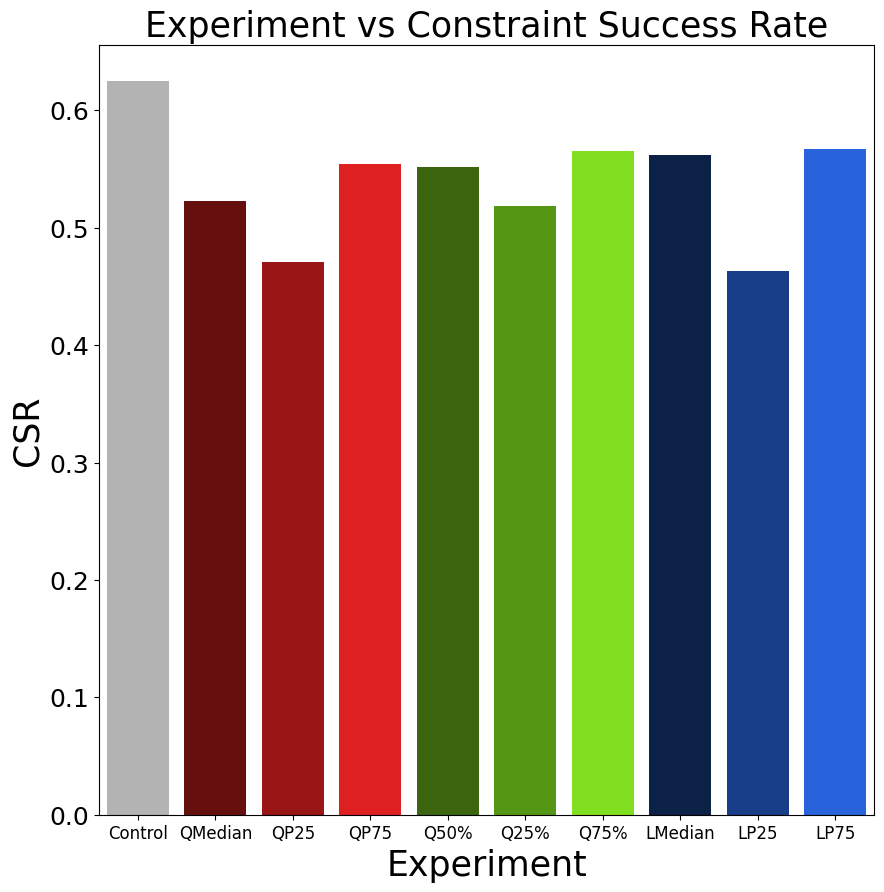

In [ ]:
csr_data = {"Category":EXPERIMENT_NAMES, "Values":csrs}
plt.figure(figsize=(10, 10))
colors = color_array
sns.barplot(x='Category', y='Values', data=csr_data, palette = colors, ci='sd')

plt.title('Experiment vs Constraint Success Rate', fontsize=25)
plt.xlabel('Experiment', fontsize=25)
plt.ylabel('CSR', fontsize=25)
plt.xticks(fontsize=12)
plt.yticks(fontsize=18)

plt.show()

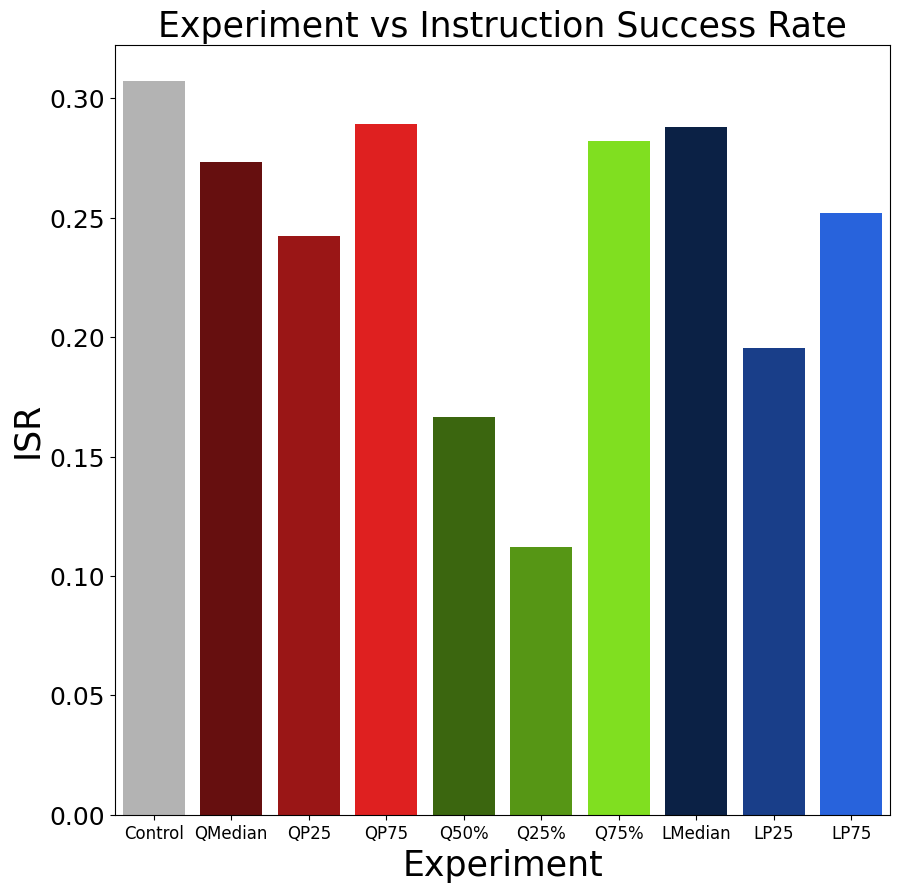

In [ ]:
isr_data = {"Category":EXPERIMENT_NAMES, "Values":isrs}
plt.figure(figsize=(10, 10))
colors = color_array
sns.barplot(x='Category', y='Values', data=isr_data, palette = colors, ci='sd')

plt.title('Experiment vs Instruction Success Rate', fontsize=25)
plt.xlabel('Experiment', fontsize=25)
plt.ylabel('ISR', fontsize=25)
plt.xticks(fontsize=12)
plt.yticks(fontsize=18)

plt.show()

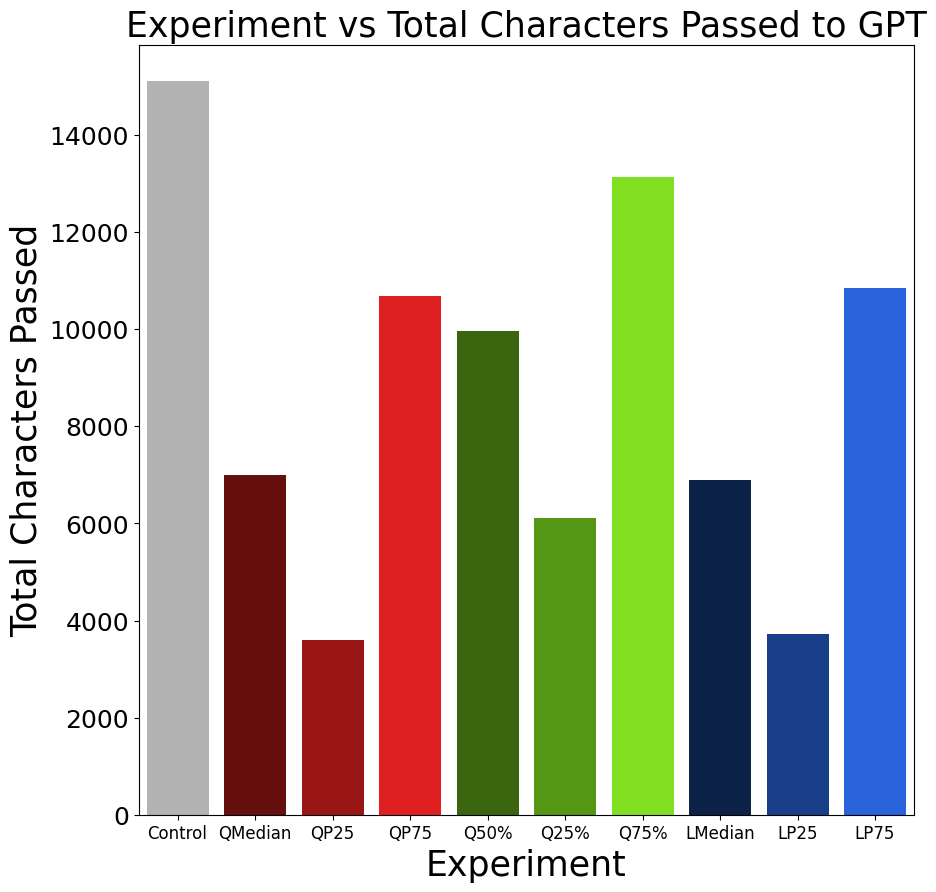

In [ ]:
inter_data = {"Category":EXPERIMENT_NAMES, "Values":passed_chars_lengths}
plt.figure(figsize=(10, 10))
colors = color_array
sns.barplot(x='Category', y='Values', data=inter_data, palette = colors, ci='sd')

plt.title('Experiment vs Total Characters Passed to GPT', fontsize=25)
plt.xlabel('Experiment', fontsize=25)
plt.ylabel('Total Characters Passed', fontsize=25)
plt.xticks(fontsize=12)
plt.yticks(fontsize=18)

plt.show()

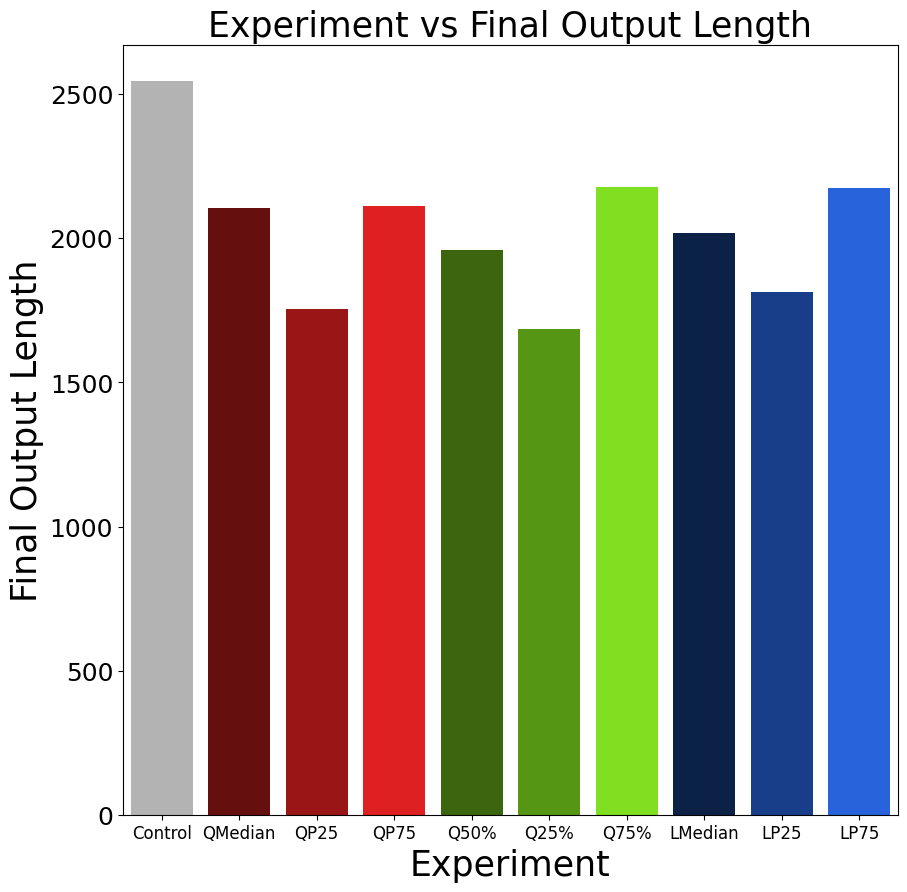

In [ ]:
final_data = {"Category":EXPERIMENT_NAMES, "Values":final_lengths}
plt.figure(figsize=(10, 10))
colors = color_array
sns.barplot(x='Category', y='Values', data=final_data, palette = colors, ci='sd')

plt.title('Experiment vs Final Output Length', fontsize=25)
plt.xlabel('Experiment', fontsize=25)
plt.ylabel('Final Output Length', fontsize=25)
plt.xticks(fontsize=12)
plt.yticks(fontsize=18)

plt.show()

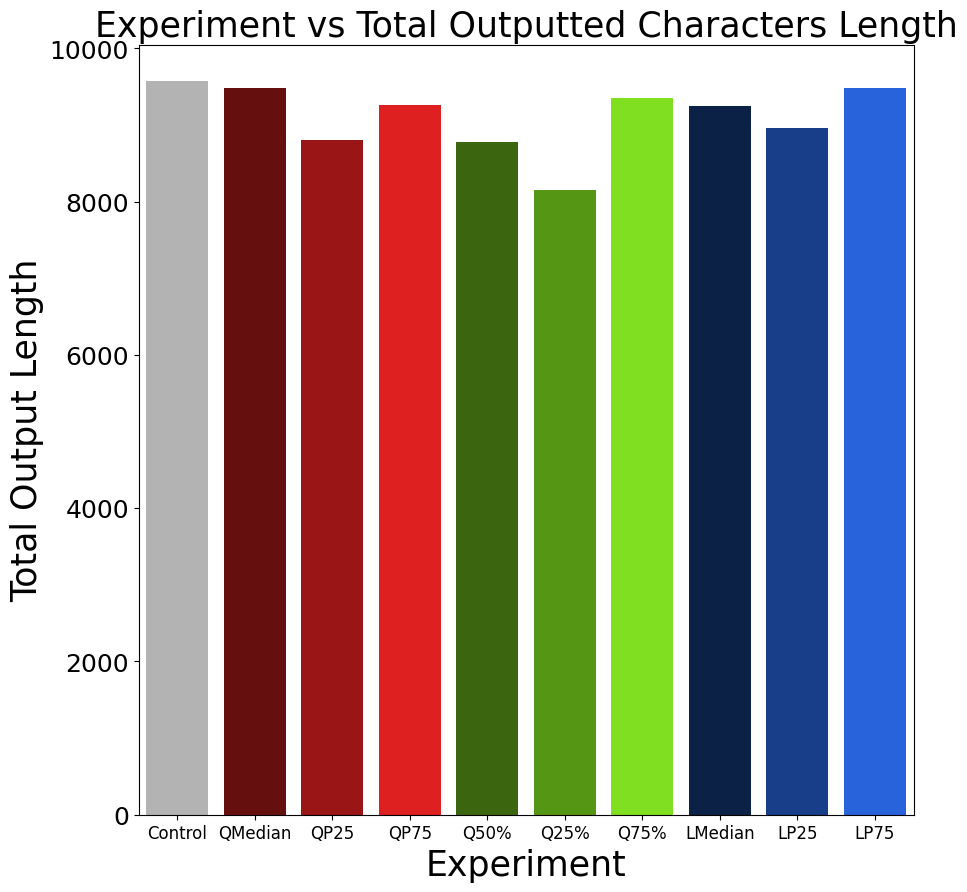

In [ ]:
output_length_data = {"Category":EXPERIMENT_NAMES, "Values":outputted_lengths}
plt.figure(figsize=(10, 10))
colors = color_array
sns.barplot(x='Category', y='Values', data=output_length_data, palette = colors, ci='sd')

plt.title('Experiment vs Total Outputted Characters Length', fontsize=25)
plt.xlabel('Experiment', fontsize=25)
plt.ylabel('Total Output Length', fontsize=25)
plt.xticks(fontsize=12)
plt.yticks(fontsize=18)

plt.show()

Stop running here - below is for compression budgets.
Below computes control run's length percentiles (median, P25, P75 for each node) to use for budget based compression

In [ ]:
CONTROL_PATH = "/content/drive/MyDrive/TokenReductionProject/Results/AgentOutputs/agent_outputs_for_eval_0.pkl"
CONTROL_JSON = "/content/drive/MyDrive/TokenReductionProject/Results/AgentOutputs/agent_outputs_for_eval_0.json"

In [ ]:
file_paths = [CONTROL_PATH]
experiment_names = ["Control"]
experiments = []

In [ ]:
import pandas as pd

# load the pickle files and data into a list (experiments)
for i in range(len(file_paths)):
    data = pd.read_pickle(file_paths[i])
    experiments.append(data)

In [ ]:
control_data = pd.read_pickle(CONTROL_PATH)
control_data.head()

,id,input,constraints,output
0,agentif:general:2:1:Thought_prompt,[{'content': ' # 任务描述 ## 角色设定 - 你是一名专家助理，可以使用代...,[{'desc': '您可以使用一系列**预设给定的函数**，可以通过直接调这些函数来完成任...,"{'role': 'assistant', 'content': '<thought> 根据..."
1,agentif:general:13:1:Thought_prompt,[{'content': ' # 任务描述 ## 角色设定 - 你是一名专家助理，可以使用代...,[{'desc': '您可以使用一系列**预设给定的函数**，可以通过直接调这些函数来完成任...,"{'role': 'assistant', 'content': '<thought> 根据..."
2,agentif:fe3f830257e5e0c86009829d8cbc7f38b728f63d,[{'content': 'You are a Budget Analysis Agent ...,[{'desc': 'Ensure percentages add up to 100%.'...,"{'role': 'assistant', 'content': '```json { ..."
3,agentif:lawglm:13:1:Code_prompt,"[{'content': '你是一名顶级的Code专家,可以使用代码块解决任何任务。你将根据...","[{'desc': '开始 <code>', 'dimension': 'example_d...","{'role': 'assistant', 'content': '<code> # 筛选出..."
4,agentif:32f3cda4540f5f1eea333880a3a3f48b3dae15d6,[{'content': 'You are a senior game mechanics ...,[{'desc': 'Design core gameplay loops that mat...,"{'role': 'assistant', 'content': '### Final Ga..."


In [ ]:
import numpy as np

def _approx_tokens(s: str) -> int:
    return max(1, len(s) // 4)  # cheap heuristic; good enough for budgeting

def compute_prompt_lengths(rows):
    if isinstance(rows, pd.DataFrame):
        rows = rows.to_dict("records")

    lengths = []

    for row in rows:
        full_input = "\n".join(str(q.get("content", "")) for q in row.get("input", []))
        if full_input:
            lengths.append(_approx_tokens(full_input))

    arr = np.array(lengths)

    return {
        "mean": float(arr.mean()),
        "median": float(np.median(arr)),
        "p90": float(np.percentile(arr, 90)),
        "p25": float(np.percentile(arr, 25)),
        "p75": float(np.percentile(arr, 75)),

    }

def compute_stage_lengths(
    rows,
    *,
    use_raw=True,
    tokenizer=None,
):
    """
    Compute per-stage length statistics from agent output rows.

    Args:
        rows: list of rows (your dataset)
        use_raw: whether to use raw_total_content (True) or total_content (False)
        tokenizer: unused (lengths are estimated with _approx_tokens, ~4 characters per token)

    Returns:
        dict: {stage: {mean, median, p90, p25, p75, count}}
    """

    STAGES = ["plan", "research", "draft", "critique", "final"]

    if isinstance(rows, pd.DataFrame):
        rows = rows.to_dict("records")

    # collect lengths
    stage_lengths = {s: [] for s in STAGES}

    for row in rows:
        output = row.get("output", {})
        content = output.get("raw_total_content" if use_raw else "total_content", {})

        for stage in STAGES:
            text = content.get(stage, "")
            if stage not in content:
              continue

            length = _approx_tokens(text)

            stage_lengths[stage].append(length)

    # compute stats
    stats = {}
    for stage, vals in stage_lengths.items():
        if not vals:
            continue

        arr = np.array(vals)

        stats[stage] = {
            "mean": float(arr.mean()),
            "median": float(np.median(arr)),
            "p90": float(np.percentile(arr, 90)),
            "p25": float(np.percentile(arr, 25)),
            "p75": float(np.percentile(arr, 75)),

            "count": len(arr),
        }

    return stats


In [ ]:
stats = compute_stage_lengths(
    control_data,
    use_raw=True,
)

prompt_stats = compute_prompt_lengths(
    control_data,
)

print(stats)
print(prompt_stats)

{'plan': {'mean': 467.984375, 'median': 323.0, 'p90': 885.6, 'p25': 77.75, 'p75': 742.5, 'count': 128}, 'research': {'mean': 214.71875, 'median': 150.0, 'p90': 400.2, 'p25': 58.0, 'p75': 251.0, 'count': 128}, 'draft': {'mean': 529.3828125, 'median': 369.5, 'p90': 1314.1, 'p25': 69.0, 'p75': 733.25, 'count': 128}, 'critique': {'mean': 542.9609375, 'median': 516.5, 'p90': 841.6999999999999, 'p25': 339.0, 'p75': 734.5, 'count': 128}, 'final': {'mean': 635.734375, 'median': 428.0, 'p90': 1636.3999999999999, 'p25': 103.0, 'p75': 754.0, 'count': 128}}
{'mean': 2019.4765625, 'median': 859.5, 'p90': 4581.599999999999, 'p25': 405.75, 'p75': 2572.75}
